# Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv')

# Data

In [3]:
print('data head:')
print(df.head())

data head:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN   

In [4]:
print('data info:')
print(df.info())

data info:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None


In [5]:
print('data describe:')
print(df.describe())

data describe:
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    0.523008   
std     257.353842    0.486592    0.836071   14.526497    1.102743   
min       1.000000    0.000000    1.000000    0.420000    0.000000   
25%     223.500000    0.000000    2.000000   20.125000    0.000000   
50%     446.000000    0.000000    3.000000   28.000000    0.000000   
75%     668.500000    1.000000    3.000000   38.000000    1.000000   
max     891.000000    1.000000    3.000000   80.000000    8.000000   

            Parch        Fare  
count  891.000000  891.000000  
mean     0.381594   32.204208  
std      0.806057   49.693429  
min      0.000000    0.000000  
25%      0.000000    7.910400  
50%      0.000000   14.454200  
75%      0.000000   31.000000  
max      6.000000  512.329200  


In [6]:
print('null data:')
print(df.isnull().sum())

null data:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [7]:
print('duplicate data:', df.duplicated().sum())

duplicate data: 0


# Data Distribution

In [8]:
sns.set_style('whitegrid')

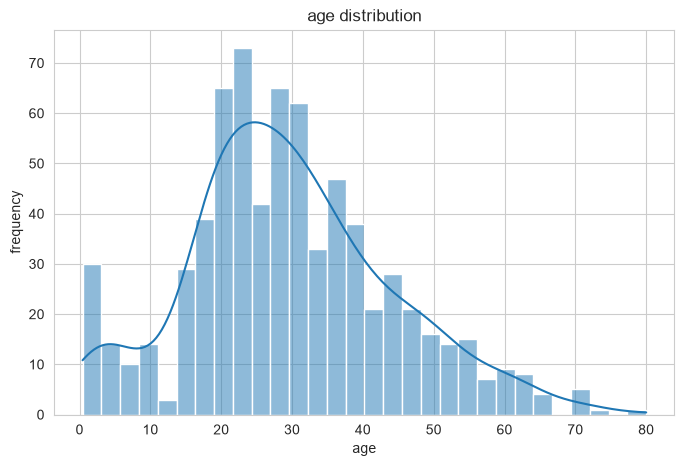

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\343560112.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Age'], palette='crest')


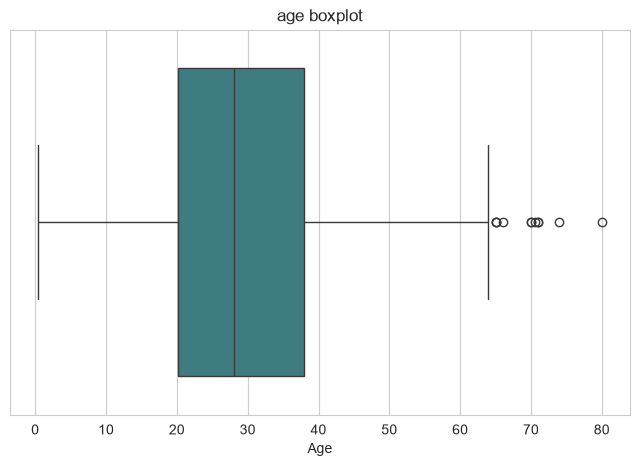

In [9]:
# age
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], kde=True, bins=30)
plt.title("age distribution")
plt.xlabel("age")
plt.ylabel("frequency")
plt.show()

print()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Age'], palette='crest')
plt.title('age boxplot')
plt.show()

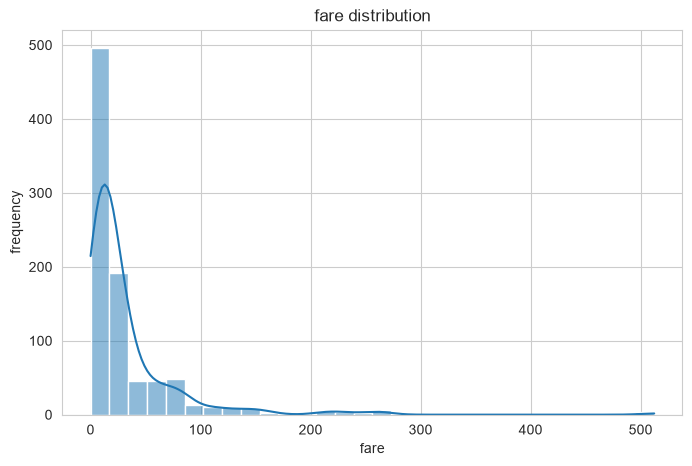

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\830665467.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Fare'], palette='crest')


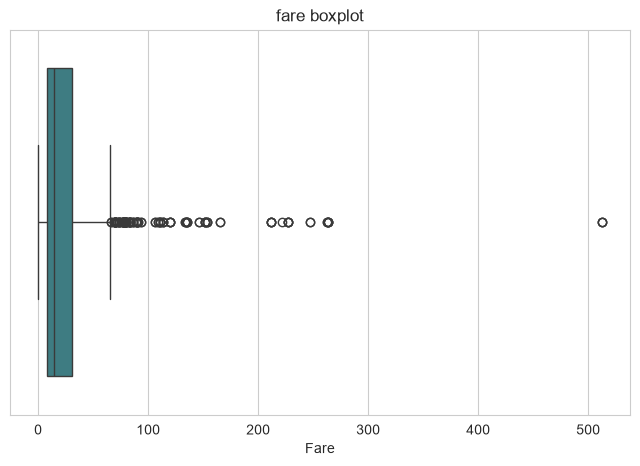

In [10]:
# fare
plt.figure(figsize=(8, 5))
sns.histplot(df['Fare'], kde=True, bins=30)
plt.title("fare distribution")
plt.xlabel("fare")
plt.ylabel("frequency")
plt.show()

print()

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Fare'], palette='crest')
plt.title('fare boxplot')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\4257353182.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survived', palette='crest')


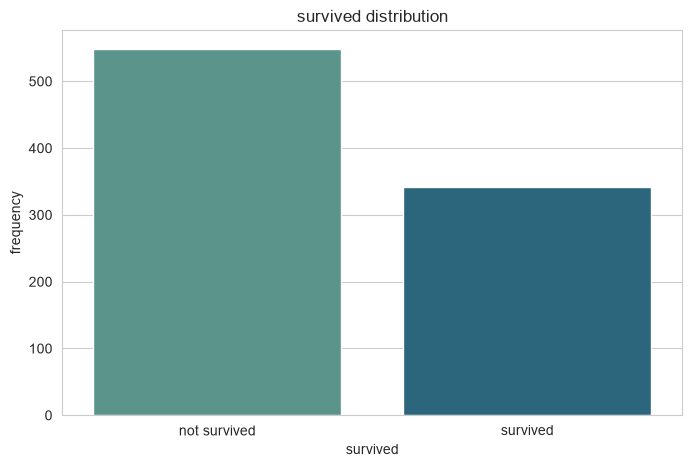

In [11]:
# survived
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Survived', palette='crest')
plt.title('survived distribution')
plt.xticks([0, 1], ['not survived', 'survived'])
plt.xlabel('survived')
plt.ylabel('frequency')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\2257149405.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Pclass', data=df, palette='crest')


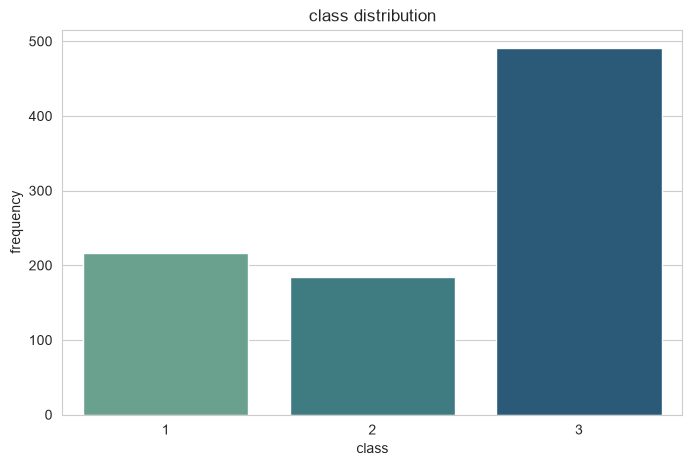

In [12]:
# pclass
plt.figure(figsize=(8, 5))
sns.countplot(x='Pclass', data=df, palette='crest')
plt.title('class distribution')
plt.xlabel('class')
plt.ylabel('frequency')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\2052821065.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Sex', data=df, palette='crest')


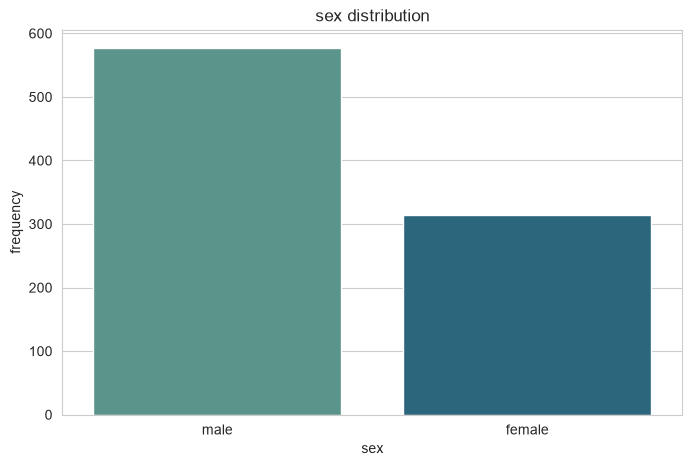

In [13]:
# sex
plt.figure(figsize=(8, 5))
sns.countplot(x='Sex', data=df, palette='crest')
plt.title('sex distribution')
plt.xlabel('sex')
plt.ylabel('frequency')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\3225602731.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='SibSp', data=df, palette='crest')


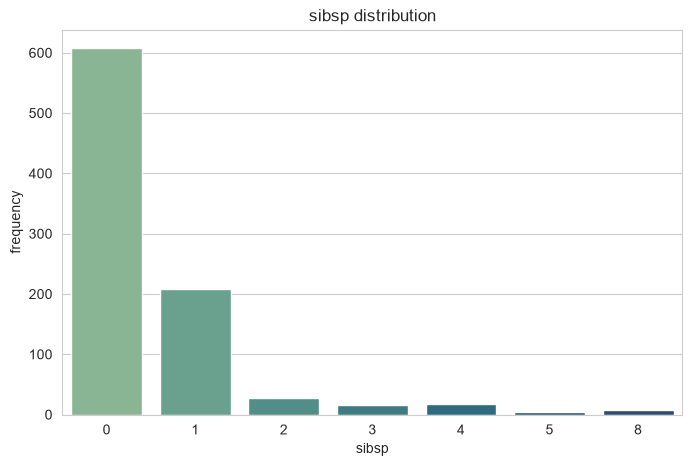

In [14]:
# sibsp
plt.figure(figsize=(8, 5))
sns.countplot(x='SibSp', data=df, palette='crest')
plt.title('sibsp distribution')
plt.xlabel('sibsp')
plt.ylabel('frequency')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\2226670727.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Parch', data=df, palette='crest')


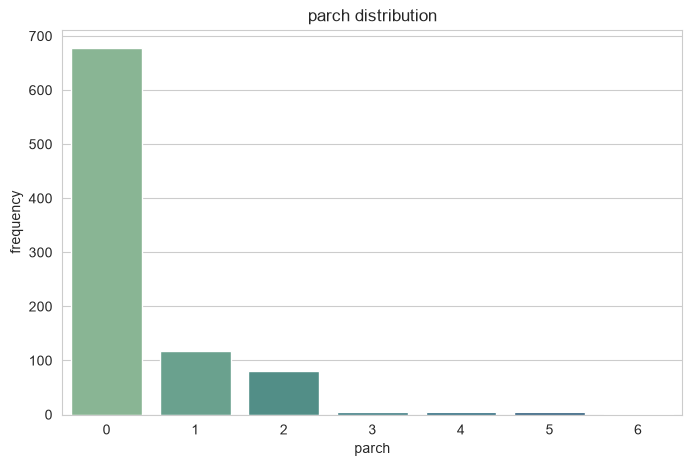

In [15]:
# parch
plt.figure(figsize=(8, 5))
sns.countplot(x='Parch', data=df, palette='crest')
plt.title('parch distribution')
plt.xlabel('parch')
plt.ylabel('frequency')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\2065543366.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Embarked', data=df, palette='crest')


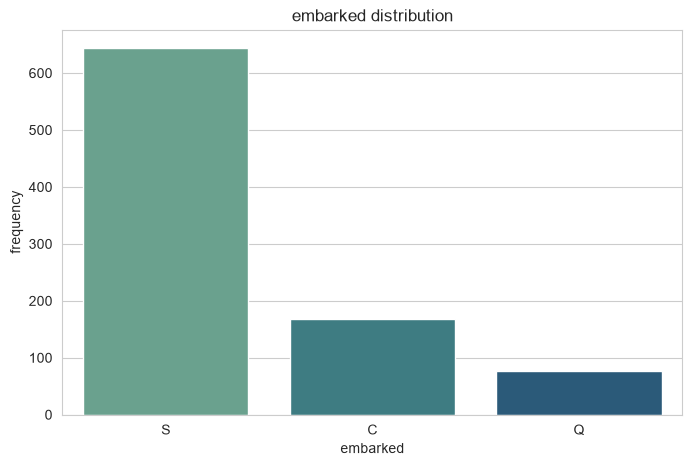

In [16]:
# embarked
plt.figure(figsize=(8, 5))
sns.countplot(x='Embarked', data=df, palette='crest')
plt.title('embarked distribution')
plt.xlabel('embarked')
plt.ylabel('frequency')
plt.show()

# Relation between data

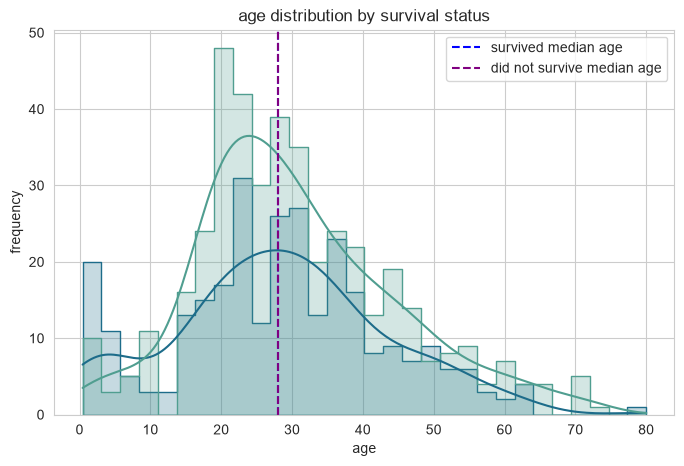

In [17]:
# age and survived
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Survived', element='step', kde=True, palette='crest', bins=30, multiple='layer')
plt.title('age distribution by survival status')
plt.xlabel('age')
plt.ylabel('frequency')
plt.axvline(df[df['Survived']==1]['Age'].median(), color='blue', linestyle='--', label='survived median age')
plt.axvline(df[df['Survived']==0]['Age'].median(), color='purple', linestyle='--', label='did not survive median age')
plt.legend()
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\779655558.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Pclass', y='Age', data=df, palette='crest')


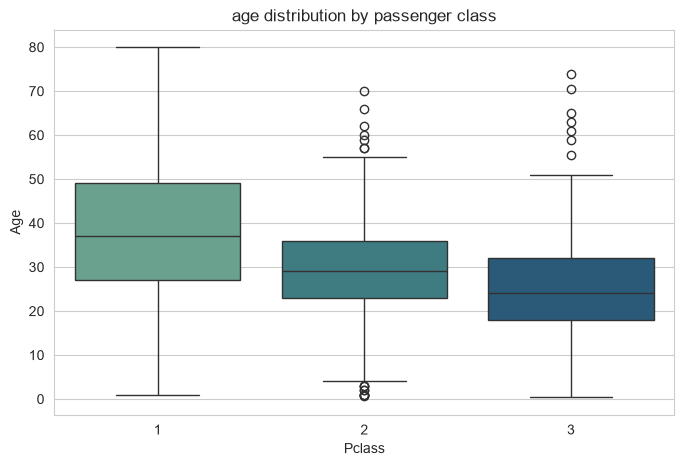

In [18]:
# age and pclass
plt.figure(figsize=(8, 5))
sns.boxplot(x='Pclass', y='Age', data=df, palette='crest')
plt.title('age distribution by passenger class')
plt.show()

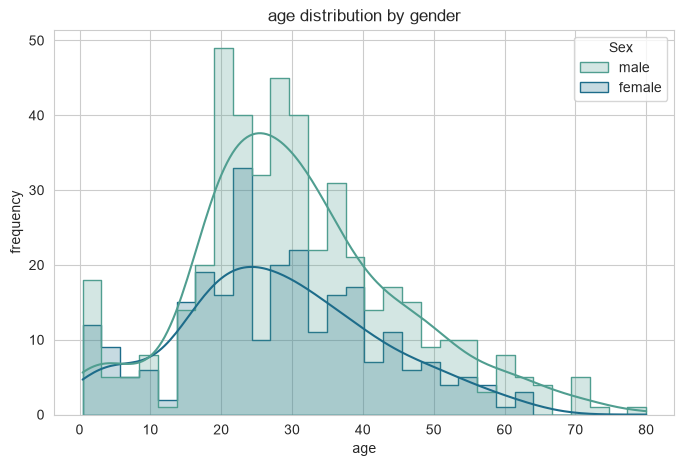

In [19]:
# age and sex
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Sex', element='step', kde=True, palette='crest', bins=30)
plt.title('age distribution by gender')
plt.xlabel('age')
plt.ylabel('frequency')
plt.show()

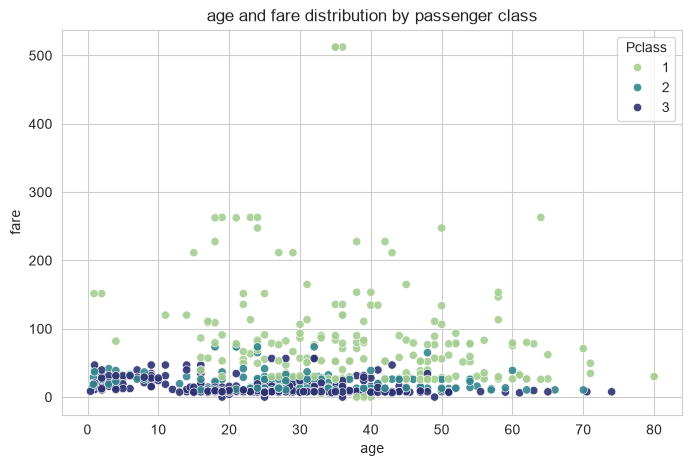

In [20]:
# age and fare
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Age', y='Fare', data=df, hue='Pclass', palette='crest', alpha=0.9)
plt.title('age and fare distribution by passenger class')
plt.xlabel('age')
plt.ylabel('fare')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\1623252164.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Pclass', y='Survived', data=df, palette='crest')


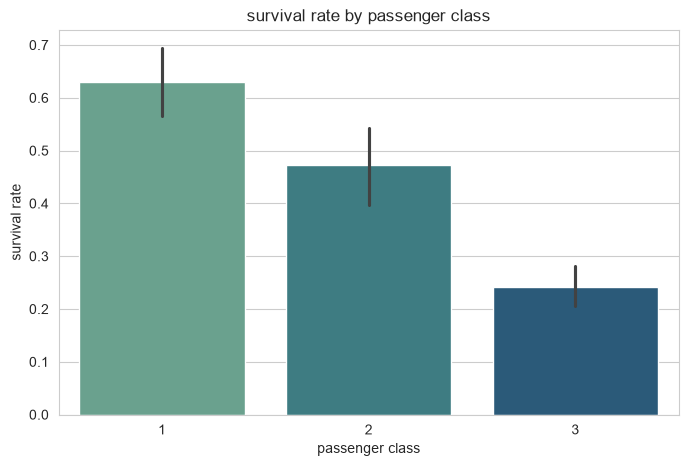

In [21]:
# survived and pclass
plt.figure(figsize=(8, 5))
sns.barplot(x='Pclass', y='Survived', data=df, palette='crest')
plt.title('survival rate by passenger class')
plt.xlabel('passenger class')
plt.ylabel('survival rate')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\1460700074.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Survived', data=df, palette='crest')


Text(0, 0.5, 'survival rate')

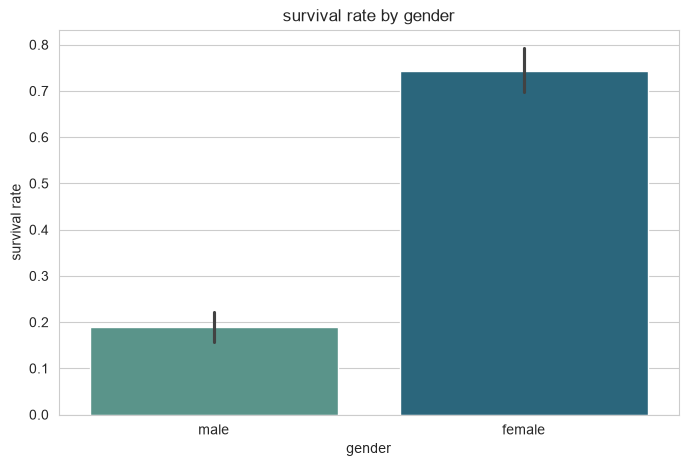

In [22]:
# survived and sex
plt.figure(figsize=(8, 5))
sns.barplot(x='Sex', y='Survived', data=df, palette='crest')
plt.title('survival rate by gender')
plt.xlabel('gender')
plt.ylabel('survival rate')

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\2076727216.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Survived', y='Fare', data=df, palette='crest')


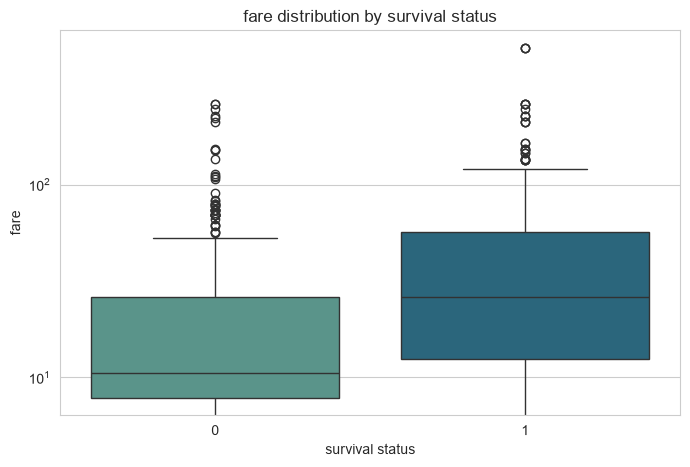

In [23]:
# fare and survived
plt.figure(figsize=(8, 5))
sns.boxplot(x='Survived', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by survival status')
plt.xlabel('survival status')
plt.ylabel('fare')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\3951223480.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Embarked', y='Survived', data=df, palette='crest')


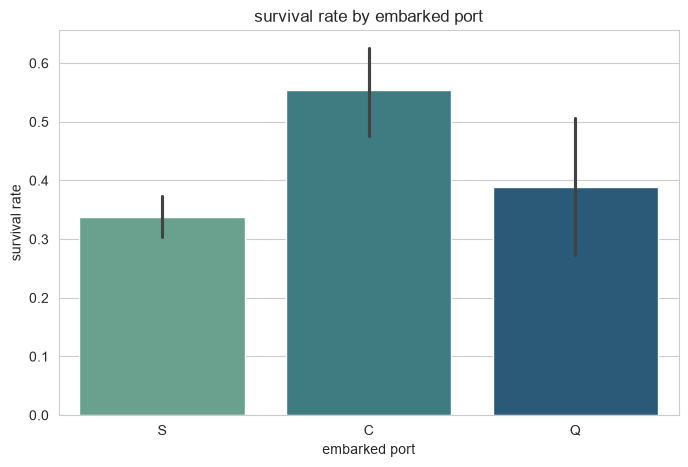

In [24]:
# survived and embarked
plt.figure(figsize=(8, 5))
sns.barplot(x='Embarked', y='Survived', data=df, palette='crest')
plt.title('survival rate by embarked port')
plt.xlabel('embarked port')
plt.ylabel('survival rate')
plt.show()

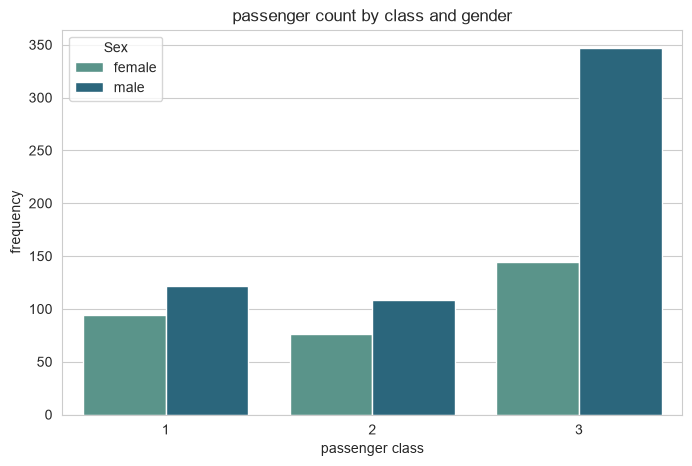

In [25]:
# pclass and sex
plt.figure(figsize=(8, 5))
sns.countplot(x='Pclass', hue='Sex', data=df, palette='crest')
plt.title('passenger count by class and gender')
plt.xlabel('passenger class')
plt.ylabel('frequency')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\3485306944.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Pclass', y='Fare', data=df, palette='crest')


Text(0, 0.5, 'fare')

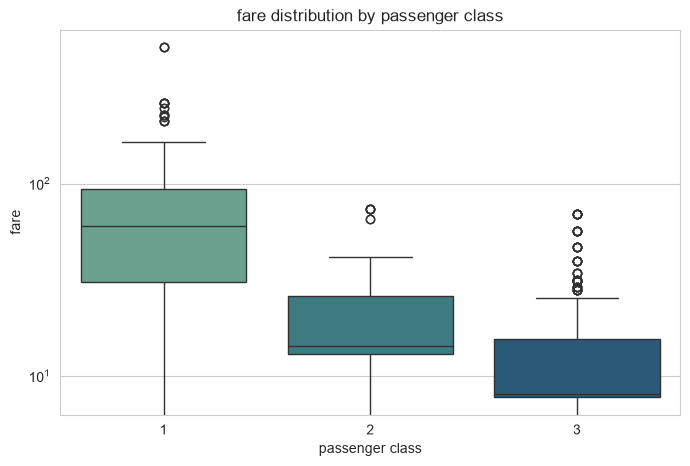

In [26]:
# pclass and fare
plt.figure(figsize=(8, 5))
sns.boxplot(x='Pclass', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by passenger class')
plt.xlabel('passenger class')
plt.ylabel('fare')

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\415699624.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Sex', y='Fare', data=df, palette='crest')


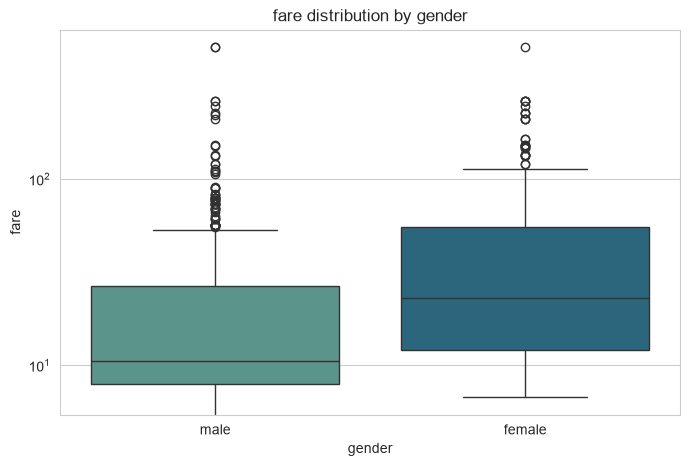

In [27]:
# sex and fare
plt.figure(figsize=(8, 5))
sns.boxplot(x='Sex', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by gender')
plt.xlabel('gender')
plt.ylabel('fare')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\2446961503.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Embarked', y='Fare', data=df, palette='crest')


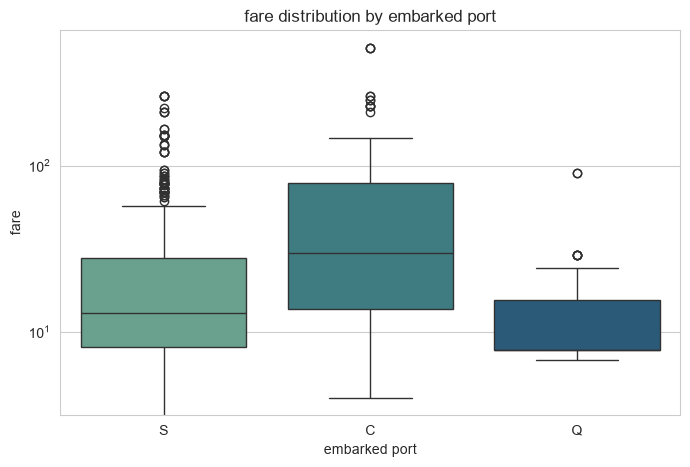

In [28]:
# embarked and fare
plt.figure(figsize=(8, 5))
sns.boxplot(x='Embarked', y='Fare', data=df, palette='crest')
plt.yscale('log')
plt.title('fare distribution by embarked port')
plt.xlabel('embarked port')
plt.ylabel('fare')
plt.show()

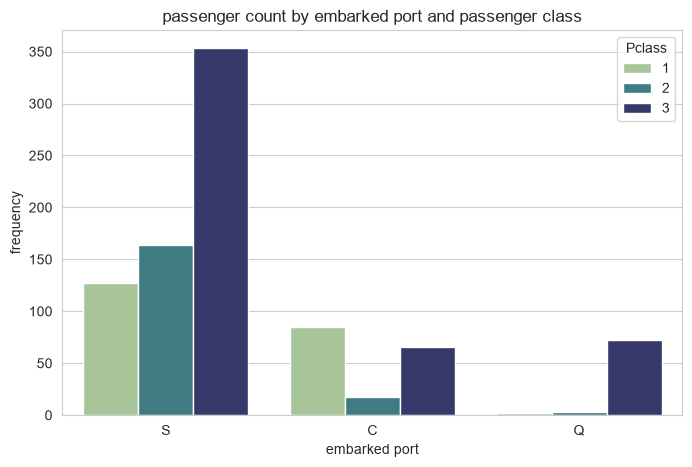

In [29]:
# embarked and pclass
plt.figure(figsize=(8, 5))
sns.countplot(x='Embarked', hue='Pclass', data=df, palette='crest')
plt.title('passenger count by embarked port and passenger class')
plt.xlabel('embarked port')
plt.ylabel('frequency')
plt.show()

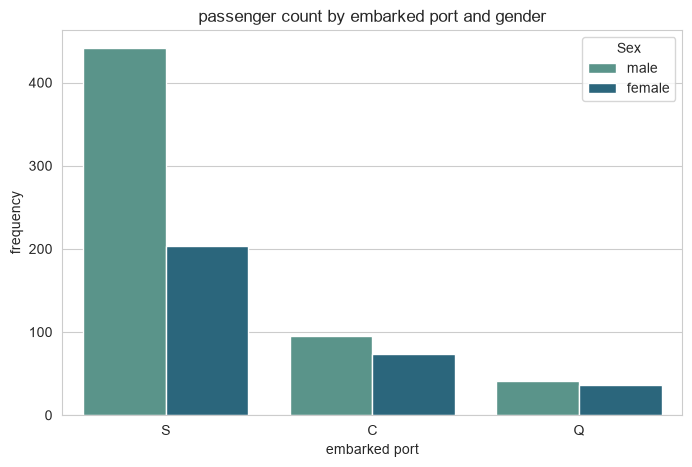

In [30]:
# embarked and sex
plt.figure(figsize=(8, 5))
sns.countplot(x='Embarked', hue='Sex', data=df, palette='crest')
plt.title('passenger count by embarked port and gender')
plt.xlabel('embarked port')
plt.ylabel('frequency')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\154943615.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='SibSp', y='Survived', data=df, palette='crest')


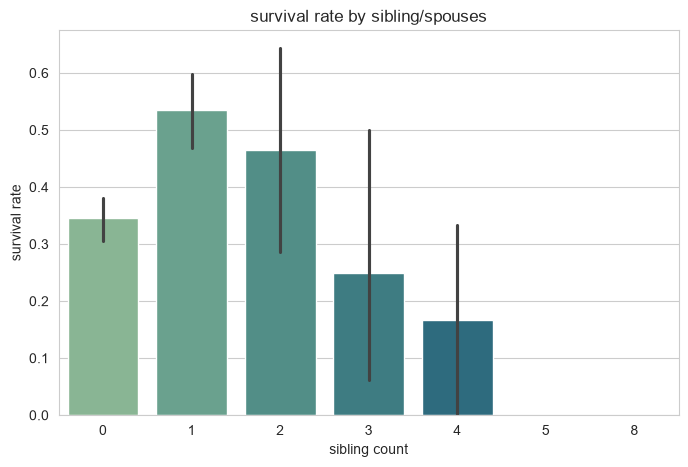

In [31]:
# sibsp and survived
plt.figure(figsize=(8, 5))
sns.barplot(x='SibSp', y='Survived', data=df, palette='crest')
plt.title('survival rate by sibling/spouses')
plt.xlabel('sibling count')
plt.ylabel('survival rate')
plt.show()

C:\Users\jorda\AppData\Local\Temp\ipykernel_10500\1762694272.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Parch', y='Survived', data=df, palette='crest')


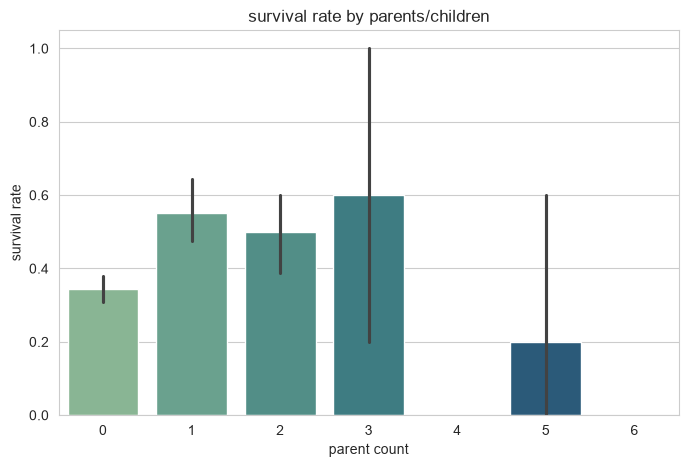

In [32]:
# parch and survived
plt.figure(figsize=(8, 5))
sns.barplot(x='Parch', y='Survived', data=df, palette='crest')
plt.title('survival rate by parents/children')
plt.xlabel('parent count')
plt.ylabel('survival rate')
plt.show()

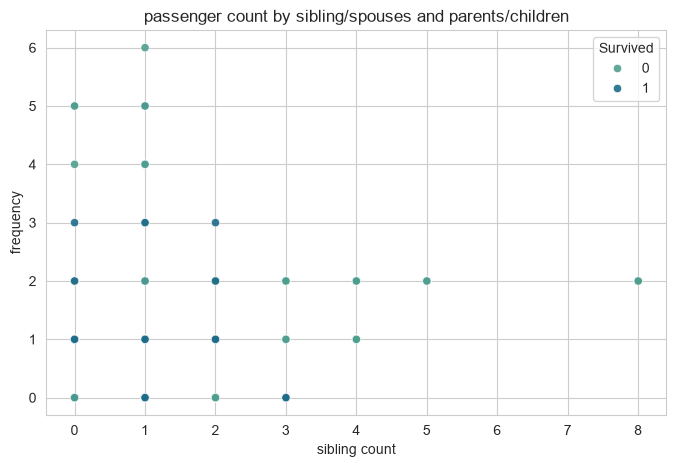

In [33]:
# sibsp and parch
plt.figure(figsize=(8, 5))
sns.scatterplot(x='SibSp', y='Parch', data=df, hue='Survived', palette='crest', alpha=0.9)
plt.title('passenger count by sibling/spouses and parents/children')
plt.xlabel('sibling count')
plt.ylabel('frequency')
plt.show()

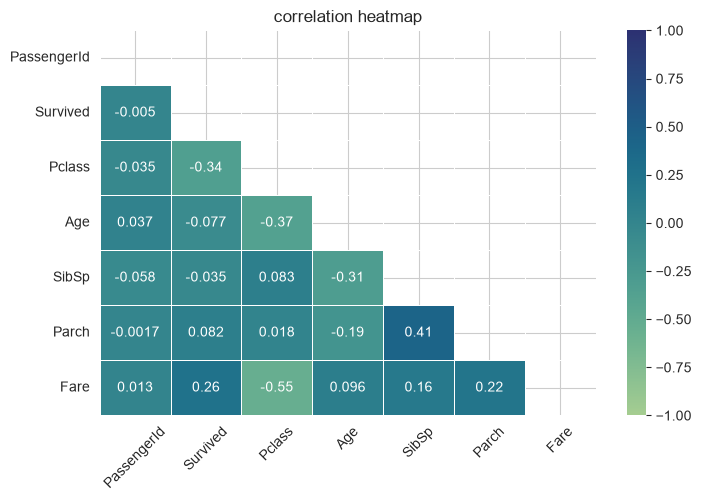

In [34]:
# Correlation heatmap
plt.figure(figsize=(8, 5))
corr = df.corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, cmap='crest', vmin=-1, vmax=1, linewidths=0.5)
plt.title('correlation heatmap')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

# Data Preprocessing

In [35]:
df_clean = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)
print(df_clean.head())

   Survived  Pclass     Sex   Age  SibSp  Parch     Fare Embarked
0         0       3    male  22.0      1      0   7.2500        S
1         1       1  female  38.0      1      0  71.2833        C
2         1       3  female  26.0      0      0   7.9250        S
3         1       1  female  35.0      1      0  53.1000        S
4         0       3    male  35.0      0      0   8.0500        S


In [36]:
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

In [37]:
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

In [38]:
print(df_clean.isnull().sum())

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [39]:
# convert sex to binary
df_clean['Sex'] = df_clean['Sex'].map({'male': 0, 'female': 1})

In [40]:
# one-hot encode embarked and pclass
df_clean = pd.get_dummies(df_clean, columns=['Embarked', 'Pclass'], drop_first=True)

In [41]:
# feature scaling
scaler = StandardScaler()
scale_cols = ['Age', 'Fare']
df_clean[scale_cols] = scaler.fit_transform(df_clean[scale_cols])

In [42]:
scaler = MinMaxScaler()
scale_cols = ['Age', 'Fare']
df_clean[scale_cols] = scaler.fit_transform(df_clean[scale_cols])

In [43]:
print("Processed Data Shape:", df_clean.shape)
print(df_clean)

Processed Data Shape: (891, 10)
     Survived  Sex       Age  SibSp  Parch      Fare  Embarked_Q  Embarked_S  \
0           0    0  0.271174      1      0  0.014151       False        True   
1           1    1  0.472229      1      0  0.139136       False       False   
2           1    1  0.321438      0      0  0.015469       False        True   
3           1    1  0.434531      1      0  0.103644       False        True   
4           0    0  0.434531      0      0  0.015713       False        True   
..        ...  ...       ...    ...    ...       ...         ...         ...   
886         0    0  0.334004      0      0  0.025374       False        True   
887         1    1  0.233476      0      0  0.058556       False        True   
888         0    1  0.346569      1      2  0.045771       False        True   
889         1    0  0.321438      0      0  0.058556       False       False   
890         0    0  0.396833      0      0  0.015127        True       False   

     Pc